<a href="https://colab.research.google.com/github/guyen5/Capstone/blob/main/notebooks/3%20Backtest%20Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 3: Backtest Engine

This notebook builds the engine that every strategy in the project runs through. Wang and Hasuike retrain their model every month on 9 months of data, which is only 72 monthly rows for the eight ETF_A funds, so the replication trains on **daily rows**: every trading day's indicators paired with the return over the next 21 trading days. The notebook builds that daily table, the training windows that say which daily rows each test month may use, and the covariance matrices. It then adds the optimizer, the monthly accounting of drift, turnover and fees, and the benchmark strategies, and checks classic Markowitz against the paper's Table 3.

**Work packages:** WBS 3.2 (Daily features and windows), 3.3 (Backtest engine) and 3.35 (Window for historical returns)

**Inputs:** `Daily Prices.parquet` from Notebook 1 and `Monthly Data.parquet` from Notebook 2

**Outputs** (Google Drive, `Capstone/data`):

| File | Folder | Contents |
|---|---|---|
| Daily Features.parquet | processed | One row per universe, ETF and trading day: 7 features, the 21-day forward return and the day it becomes known |
| Daily Training Windows.parquet / .csv | processed | For each of the 81 test months and each window (9+3, 36, 60 months): which daily rows to fit, validate and predict on |
| Covariances.parquet | processed | Sample and Ledoit-Wolf covariance matrices at every month-end, both universes |
| Benchmark Months.parquet | processed | Monthly gross and net return, fee and turnover of 1/N, minimum variance and classic Markowitz |
| Markowitz Window Diagnostic.csv | reports | Classic Markowitz turnover, volatility and Sharpe ratio for each averaging window, next to the paper |
| Benchmark Results.csv | reports | Return, volatility, Sharpe ratio, drawdown and turnover of each benchmark, next to the paper's values |
| Daily Data Checks.csv | reports | Results of all checks |
| Variables.csv | processed | Definition of every column, including the new tables |

**Timing rule:** a daily row dated d holds features known at the close of d. Its target is the return from d to 21 trading days later, so the row can be used for training only from that later day (its `label_date`) onward. Section 4 checks this directly.

## 1. Setup

Connects Google Drive, where all data files are stored, and loads the project code from the GitHub repository. Run this cell first in every new Colab session. When Colab asks for access, choose the Google account that holds the `Capstone/data` folder.

**GitHub token (only if the repository is private).** The repository is public, so no token is needed. If it is ever made private, create a read-only fine-grained token on GitHub for the Capstone repository and add it in Colab's Secrets panel (key icon) as `GITHUB_TOKEN`, with notebook access turned on.

In [27]:
# Connect Google Drive. All data files are read from and saved to
# MyDrive/Capstone/data.
from google.colab import drive, userdata
drive.mount("/content/drive")

import os
import shutil
import subprocess
import sys

REPO = "guyen5/Capstone"
REPO_DIR = "/content/Capstone"

# The repository is public, so no login is needed. A GitHub token stored as
# the Colab secret GITHUB_TOKEN is used only if one exists, in case the
# repository is ever made private.
try:
    token = userdata.get("GITHUB_TOKEN")
except Exception:
    token = None
url = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"

# Download a fresh copy of the code on every run, so the notebook always
# uses the latest version on GitHub. Stop if the download fails rather than
# run on an old copy.
shutil.rmtree(REPO_DIR + "_new", ignore_errors=True)
result = subprocess.run(["git", "clone", "--quiet", url, REPO_DIR + "_new"],
                        capture_output=True, text=True)
if result.returncode != 0:
    raise RuntimeError("Could not download the code from GitHub. Check that the repository "
                       "guyen5/Capstone is public, or add a GitHub token as the Colab secret GITHUB_TOKEN.")
shutil.rmtree(REPO_DIR, ignore_errors=True)
os.rename(REPO_DIR + "_new", REPO_DIR)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Install the pinned library versions listed in requirements.txt.
%pip install --quiet -r {REPO_DIR}/requirements.txt

# Make the project modules importable with "from src import ...".
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
import importlib
import json
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, cleaning, features, windows, covariance, variables, optimizer, backtest

# Reload the modules so code changes pulled from GitHub take effect
# without restarting the Colab runtime.
for module in (config, cleaning, features, windows, covariance, variables, optimizer, backtest):
    importlib.reload(module)

DIRS = config.data_dirs()
pd.set_option("display.width", 160)

## 2. Load the inputs

Reads the clean daily prices from Notebook 1 and the monthly table from Notebook 2. The monthly table is used only to confirm that the daily table gives the same features at every month-end.

In [29]:
clean = cleaning.load_clean(DIRS["processed"])
panel = pd.read_parquet(DIRS["processed"] / config.FILES["monthly"])
raw_info = json.loads((DIRS["raw"] / config.FILES["raw_info"]).read_text())

print(f"Daily prices: {len(clean):,} rows, {clean['ticker'].nunique()} ETFs, "
      f"{clean['date'].min():%Y-%m-%d} to {clean['date'].max():%Y-%m-%d}")
print(f"Monthly Data: {len(panel):,} rows, {panel['date'].nunique()} month-ends")
print("Raw file checksum:", raw_info["md5"])

Daily prices: 71,408 rows, 16 ETFs, 2009-01-02 to 2026-09-30
Monthly Data: 3,618 rows, 201 month-ends
Raw file checksum: 80113beee459649ee81eda775e0eee79


## 3. Daily features table

The same seven indicators as the monthly table, now kept for every trading day from January 2010, together with the target.

| Column | Meaning |
|---|---|
| `month_end` | True on the last trading day of a month, the days on which the portfolio is rebalanced |
| seven features | Momentum, trend, price bias, RSI, MACD, Bollinger width, volume bias (as in Notebook 2) |
| `fwd_return` | Return over the next 21 trading days |
| `fwd_rel_return` | That return minus the average of the universe over the same days. This is the forecast target: with weights summing to one, only the differences between ETFs move the portfolio, and removing the common market move takes out the largest source of forecast error |
| `label_date` | The day the forward return becomes known |

Neighbouring rows overlap: two consecutive days share 20 of their 21 target days. The training windows in section 5 and the bootstrap in Notebook 5 are built around this. The last 21 trading days have features but no target yet.

In [30]:
daily = features.daily_features(clean)
daily_table = features.build_daily_table(clean, daily)

print(daily_table.groupby("universe").agg(rows=("date", "size"),
                                         days=("date", "nunique"),
                                         month_ends=("month_end", "sum")))
print(f"Rows without a target yet: {daily_table['fwd_return'].isna().sum()} "
      f"(the last {config.FORWARD_DAYS} trading days)")
daily_table.head()

           rows  days  month_ends
universe                         
ETF_A     33688  4211        1608
ETF_B     42110  4211        2010
Rows without a target yet: 378 (the last 21 trading days)


,date,universe,ticker,month_end,momentum,trend,price_bias,rsi,macd,bollinger,volume_bias,volume_filled,fwd_return,fwd_rel_return,label_date
0,2010-01-04,ETF_A,AGG,False,-0.013488,-0.005165,-0.002110,38.187265,-0.001171,0.022089,0.073163,False,0.010904,0.050842,2010-02-03
1,2010-01-04,ETF_A,DBC,False,0.022842,0.006514,0.035232,65.811693,0.004887,0.077379,0.197228,False,-0.070919,-0.030980,2010-02-03
2,2010-01-04,ETF_A,EEM,False,0.028677,0.014971,0.040634,65.820781,0.003376,0.061685,0.594388,False,-0.077499,-0.037560,2010-02-03
3,2010-01-04,ETF_A,EFA,False,0.004311,0.003156,0.023990,60.255482,0.002296,0.044995,0.400854,False,-0.052353,-0.012414,2010-02-03
4,2010-01-04,ETF_A,JPXN,False,0.025332,0.022178,0.015982,59.858604,-0.000414,0.027194,-0.471496,False,0.008511,0.048450,2010-02-03


## 4. Checks on the daily table

Confirms the table is complete and that the target is correct:

- one row per ETF per trading day, no duplicates, no missing features;
- every target becomes known after its row date, and only the last 21 days lack one;
- relative returns sum to zero across each universe on each day;
- the forward return and its label date, recomputed independently from the price table for 200 random rows;
- at every month-end, the features equal those in the monthly table, which already passed the look-ahead test in Notebook 2.

Every column is also checked against the Variables list. The notebook stops on any FAIL.

In [31]:
daily_checks = features.validate_daily(daily_table, clean, panel)
daily_columns = variables.check_table(daily_table, "Daily Features")

print(daily_checks.to_string(index=False))
print()
print(daily_columns.to_string(index=False))

checks = [daily_checks.assign(table="Daily Features"),
          daily_columns.assign(table="Daily Features")]
if (pd.concat(checks)["status"] == "FAIL").any():
    raise RuntimeError("A check failed. The daily table should not be used.")

                        check status                                           detail
              row count ETF_A   PASS        33,688 rows = 4,211 trading days x 8 ETFs
              row count ETF_B   PASS       42,110 rows = 4,211 trading days x 10 ETFs
                  unique rows   PASS                                 0 duplicate keys
            features complete   PASS                         0 missing feature values
        newest days unlabeled   PASS      the last 21 trading days have no target yet
         label after row date   PASS    every target becomes known after its row date
    relative returns sum to 0   PASS               largest absolute daily sum 5.6e-16
            target recomputed   PASS      200 random rows, largest difference 0.0e+00
month-ends match Monthly Data   PASS 3,618 month-end rows, largest difference 0.0e+00

  check         column status                                    detail
columns            all   PASS       same columns and order as Varia

## 5. Daily training windows

For each of the 81 test months, the window says which daily rows the model may use. A row is usable on the decision date only if its target is already known (`label_date` on or before the decision date). The window covers the most recent months of usable rows, and its last months are the validation slice used to tune settings.

| Window | Length | Validation | Used for |
|---|---|---|---|
| 9+3 | 12 months | last 3 months | The replication, as in Wang and Hasuike |
| 36 | 36 months | last 12 months | Candidate for the main test |
| 60 | 60 months | last 12 months | Candidate for the main test |

The main test uses one of the three, chosen on 2015 to 2019 data before any test result is seen (WBS 5.3).

**Gap before validation.** A training row from the last days before the validation slice would have a target that runs into the validation period, so tuning would see validation returns. Rows are therefore fitted only if their target is known before validation starts (`fit_end`), which leaves a gap of 21 trading days. After tuning, the model is refit on all rows up to `train_end`.

In [32]:
all_daily_windows = {w: windows.daily_windows(daily_table, w) for w in config.DAILY_WINDOWS}
daily_window_table = pd.concat(all_daily_windows.values(), ignore_index=True)

for w, table in all_daily_windows.items():
    print(f"Window: {w}")
    report = windows.check_daily_windows(table, daily_table)
    print(report.to_string(index=False))
    print()
    checks.append(report.assign(table=f"Daily Training Windows {w}"))

window_columns = variables.check_table(daily_window_table, "Daily Training Windows")
checks.append(window_columns.assign(table="Daily Training Windows"))
print("Column checks:", window_columns["status"].value_counts().to_dict())

# Rows in the first test month (January 2020) for each window, ETF_A.
sizes = []
for w, table in all_daily_windows.items():
    fit, val, test = windows.daily_rows_for(daily_table, table.iloc[0], "ETF_A")
    sizes.append({"window": w, "fit rows": len(fit), "validation rows": len(val),
                  "prediction rows": len(test)})
print(pd.DataFrame(sizes).to_string(index=False))

all_daily_windows["9+3"].iloc[[0, 1, -1]]

Window: 9+3
                    check status                                                         detail
targets known at decision   PASS the newest training row's target is known on the decision date
    gap before validation   PASS   every fit target is known before the validation slice starts
           dates in order   PASS      train start < fit end < validation < train end < decision
              test period   PASS                             81 test months, 2020-01 to 2026-09

Window: 36
                    check status                                                         detail
targets known at decision   PASS the newest training row's target is known on the decision date
    gap before validation   PASS   every fit target is known before the validation slice starts
           dates in order   PASS      train start < fit end < validation < train end < decision
              test period   PASS                             81 test months, 2020-01 to 2026-09

Window: 60
    

,month,decision_date,train_start,fit_end,validation_start,train_end,train_months,validation_months,window
0,2020-01,2019-12-31,2018-11-30,2019-07-31,2019-08-30,2019-11-29,12,3,9+3
1,2020-02,2020-01-31,2019-01-02,2019-08-29,2019-10-01,2019-12-31,12,3,9+3
80,2026-09,2026-08-31,2025-08-01,2026-03-31,2026-05-01,2026-07-31,12,3,9+3


## 6. Covariance matrices

At every month-end, the covariance of the ETFs' daily returns over the last 220 trading days, scaled to a monthly horizon (times 21). Two estimates are saved:

- **sample**: the plain sample covariance plus 10⁻⁶ on the diagonal, as in Wang and Hasuike. Used by the replication.
- **ledoit_wolf**: the sample covariance shrunk toward a scaled identity matrix, with the intensity chosen from the data (Ledoit and Wolf, 2004). Used by the robust model. SPY and VTI move almost together, which makes the sample matrix poorly conditioned; shrinkage reduces this.

The checks confirm that every matrix is complete, symmetric and positive definite, that each window ends at its decision date, and that the sample estimate matches an independent calculation.

In [33]:
month_ends = features.month_ends(clean)
month_ends = month_ends[month_ends >= pd.Timestamp(config.PANEL_START)]
cov_table = covariance.build_covariances(clean, month_ends)

cov_checks = covariance.validate_covariances(cov_table, clean)
cov_columns = variables.check_table(cov_table, "Covariances")
print(cov_checks.to_string(index=False))
print("Column checks:", cov_columns["status"].value_counts().to_dict())
checks += [cov_checks.assign(table="Covariances"), cov_columns.assign(table="Covariances")]

all_checks = pd.concat(checks, ignore_index=True)
if (all_checks["status"] == "FAIL").any():
    raise RuntimeError("A check failed. The covariance table should not be used.")

                    check status                                                                   detail
        complete matrices   PASS                                            804 matrices, every one N x N
                symmetric   PASS                                                largest asymmetry 0.0e+00
        positive definite   PASS                                             smallest eigenvalue 2.38e-05
shrinkage between 0 and 1   PASS                              intensity from 0.015 to 0.145, median 0.027
            no look-ahead   PASS              every window is the 220 returns ending at the decision date
        sample recomputed   PASS 3 random dates checked against pandas .cov(), largest difference 0.0e+00
Column checks: {'PASS': 9}


### 6a. How much the covariance is shrunk, and why

The left panel shows the Ledoit-Wolf shrinkage intensity at each month-end. The right panel shows the condition number of each matrix (largest eigenvalue divided by the smallest). A large value means some combinations of ETFs look almost riskless only because of estimation noise, and the optimizer leans on them.

On ETF_A the intensity is small, mostly 2 to 4 percent, and rises only in turbulent periods such as 2020 and 2025. Even so, it cuts the median condition number from about 435 to about 172. With 220 days and at most 10 ETFs, the sample matrix is already reasonably estimated, so Ledoit-Wolf is a mild correction here rather than a large change.

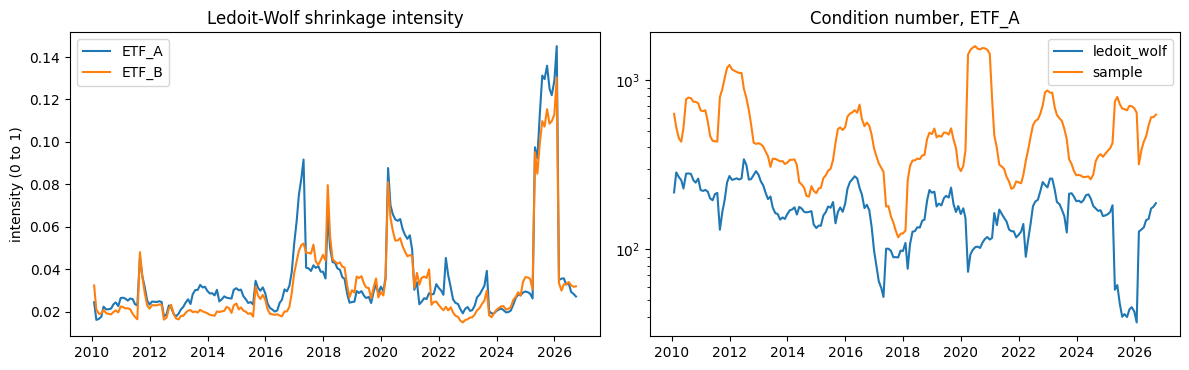

method
ledoit_wolf    172.0
sample         435.0


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
keys = cov_table.drop_duplicates(["date", "universe", "method"])
for uni in ("ETF_A", "ETF_B"):
    k = keys[(keys["universe"] == uni) & (keys["method"] == "ledoit_wolf")]
    axes[0].plot(k["date"], k["shrinkage"], label=uni)
axes[0].set_title("Ledoit-Wolf shrinkage intensity")
axes[0].set_ylabel("intensity (0 to 1)")
axes[0].legend()

cond = []
for (d, u, m), g in cov_table[cov_table["universe"] == "ETF_A"].groupby(["date", "universe", "method"]):
    ev = np.linalg.eigvalsh(g.pivot(index="row", columns="col", values="value").to_numpy())
    cond.append({"date": d, "method": m, "condition": ev.max() / ev.min()})
cond = pd.DataFrame(cond)
for m, g in cond.groupby("method"):
    axes[1].plot(g["date"], g["condition"], label=m)
axes[1].set_yscale("log")
axes[1].set_title("Condition number, ETF_A")
axes[1].legend()
plt.tight_layout()
plt.show()

print(cond.groupby("method")["condition"].median().round(0).to_string())

## 7. The optimizer

Every strategy chooses its portfolio by solving the same problem at each month-end (the paper's Eq. 30):

maximize μᵀw − λ wᵀΣw − κ‖w − w_prev‖₁, subject to the weights summing to 1 and none being negative.

Here μ is the expected monthly return of each ETF, Σ the monthly covariance, w_prev the portfolio held just before trading, λ the risk aversion and κ the trading penalty. Strategies differ only in what they feed in: classic Markowitz uses historical average returns, plain PTO model forecasts, robust PTO the Black-Litterman means. The problem is solved with cvxpy.

The checks run the solver on 200 random problems of the size used here and confirm that the answer is valid and optimal, and that it behaves as the theory says in three limiting cases: a very large trading penalty means no trade, almost no risk aversion puts everything in the ETF with the highest μ, and equal μ gives the minimum-variance portfolio.

In [35]:
opt_checks = optimizer.check_optimizer()
print(opt_checks.to_string(index=False))
checks.append(opt_checks.assign(table="Optimizer"))
if (opt_checks["status"] == "FAIL").any():
    raise RuntimeError("An optimizer check failed.")

           check status                                                                           detail
     constraints   PASS                                   200 random problems, largest violation 2.2e-16
         optimal   PASS no rival portfolio scores higher (largest excess 8e-17, within solver tolerance)
   no-trade band   PASS                                  with kappa = 10 the portfolio is left unchanged
          corner   PASS                       with lam near 0, all weight in the ETF with the highest mu
minimum variance   PASS                              matches the closed form, largest difference 1.9e-10


## 8. Monthly accounting

At each decision date the strategy picks target weights using data up to that close, trades at the close, and earns the following month's return. During the month the weights drift with prices, so next month starts from the drifted weights, not the target.

| Quantity | Definition |
|---|---|
| Value traded | Σ \|target − pre-trade weight\| |
| Turnover | Half the value traded; a full switch from one ETF to another counts as 1 |
| Fee | 0.5% of the value traded |
| Gross return | Σ target weight × ETF return |
| Net return | Gross return minus fee |
| Next pre-trade weights | target × (1 + ETF return) / (1 + gross return) |

The first decision starts from equal weights. Annual return is 12 times the mean monthly net return, volatility the monthly standard deviation times √12, and the Sharpe ratio their ratio with no risk-free rate. These match the paper, whose Sharpe ratios equal return divided by volatility in every row of Table 3.

The cell below walks through one month by hand (classic Markowitz with λ = 10 on ETF_A, the first month after January 2020 in which it trades) and compares every number with the engine. Section 9 then recomputes every month of every run.

In [36]:
returns = {u: backtest.holding_returns(panel, u) for u in ("ETF_A", "ETF_B")}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in returns}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in returns}

months, weights = backtest.run(backtest.mean_variance(hist_mu["ETF_A"], cov_sample["ETF_A"], 10),
                               returns["ETF_A"])
k = int(months.index[(months.index > 0) & (months["turnover"] > 0.01)][0])
d = months.loc[k, "date"]
w = weights[weights["date"] == d].set_index("ticker")[["before", "target"]]
w["return"] = returns["ETF_A"].loc[d]
w["trade"] = w["target"] - w["before"]
print(f"Decision date {d:%Y-%m-%d}, holding month {months.loc[k, 'month']}")
print((w * 100).round(2).rename(columns=lambda c: c + " (%)").to_string())

traded = w["trade"].abs().sum()
by_hand = {"turnover": traded / 2, "fee": config.FEE * traded,
           "gross": (w["target"] * w["return"]).sum()}
by_hand["net"] = by_hand["gross"] - by_hand["fee"]
engine = months.loc[k]
print()
print(pd.DataFrame({"by hand": by_hand, "engine": engine[list(by_hand)]}).astype(float).round(6).to_string())
assert all(abs(by_hand[k] - engine[k]) < 1e-12 for k in by_hand)

Decision date 2020-01-31, holding month 2020-02
        before (%)  target (%)  return (%)  trade (%)
ticker                                               
SPY          12.41       12.41       -7.92       0.00
VTI          12.41       12.41       -8.00       0.00
XLK          18.37       21.46       -7.30       3.09
EFA          12.07        0.00       -7.77     -12.07
EEM           0.00        0.00       -3.78       0.00
JPXN         12.08        3.85       -8.77      -8.23
AGG          32.66       49.87        1.58      17.21
DBC           0.00        0.00       -6.65       0.00

           by hand    engine
turnover  0.203023  0.203023
fee       0.002030  0.002030
gross    -0.030894 -0.030894
net      -0.032924 -0.032924


## 9. Benchmarks and classic Markowitz

Three benchmarks are run on both universes over the 81 test months, all charged the same 0.5% fee:

- **1/N**: equal weights, rebalanced back to equal every month.
- **Minimum variance**: the lowest-risk portfolio from the sample covariance, ignoring expected returns.
- **Classic Markowitz** (the paper's MVO baseline): the optimizer with μ equal to the mean daily return over the last 126 trading days, times 21, and κ = 0.005, for each λ in the paper's grid. The 126-day window is chosen in section 10.

The paper reports classic Markowitz in Table 3, so the table below sets the results side by side. Exact agreement is not expected: the data source, the start portfolio and several definitions are not stated in the paper (see the Replication Spec). What should match is the pattern. Volatility should fall steadily as λ rises, which also confirms that the covariance is on the paper's monthly scale. Turnover should stay low, from about 5% to 25% a month. At λ = 0.1 the portfolio should hold one or two ETFs.

The paper's turnover figures are multiples of 1/70 and 1/71, which suggests its test ends about 70 months after January 2020, earlier than September 2026. The comparison is therefore shown for both the full 81 months and the first 70 (to October 2025).

In [37]:
runs = []
for u in ("ETF_A", "ETF_B"):
    n = len(returns[u].columns)
    plans = [("1/N", np.nan, backtest.equal_weight(n)),
             ("Minimum variance", np.nan, backtest.minimum_variance(cov_sample[u]))]
    plans += [("Classic Markowitz", lam, backtest.mean_variance(hist_mu[u], cov_sample[u], lam))
              for lam in config.LAMBDA_GRID]
    for name, lam, strategy in plans:
        m, w = backtest.run(strategy, returns[u])
        report = backtest.check_accounting(m, w, returns[u])
        checks.append(report.assign(table=f"Backtest {u} {name} {lam}"))
        runs.append(m.assign(strategy=name, universe=u, lam=lam))

benchmark_months = pd.concat(runs, ignore_index=True)[
    ["strategy", "universe", "lam", "date", "month", "gross", "fee", "net", "turnover", "held", "effective_n"]]
acc = pd.concat([c for c in checks if c["table"].iloc[0].startswith("Backtest")])
print(f"Accounting checks: {len(acc)} run, {(acc['status'] == 'FAIL').sum()} failed")
if (acc["status"] == "FAIL").any():
    raise RuntimeError("An accounting check failed.")
bm_columns = variables.check_table(benchmark_months, "Benchmark Months")
checks.append(bm_columns.assign(table="Benchmark Months"))
print("Column checks:", bm_columns["status"].value_counts().to_dict())

def summarize(rows):
    return pd.DataFrame([backtest.metrics(g).rename((s, u, l))
                         for (s, u, l), g in rows.groupby(["strategy", "universe", "lam"], dropna=False)])

full = summarize(benchmark_months)
first70 = summarize(benchmark_months[benchmark_months["month"] <= config.PAPER_LAST_MONTH])
cols = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover", "effective_n"]
print()
print(full[cols].round(4).to_string())

Accounting checks: 70 run, 0 failed
Column checks: {'PASS': 12}

                              ann_return  ann_vol  sharpe  max_drawdown  turnover  effective_n
1/N               ETF_A NaN       0.1252   0.1330  0.9411       -0.2070    0.0112       8.0000
                  ETF_B NaN       0.1481   0.1712  0.8652       -0.2340    0.0135      10.0000
Classic Markowitz ETF_A 0.1       0.1815   0.1852  0.9800       -0.2006    0.0901       1.0666
                        1.0       0.1682   0.1698  0.9907       -0.1700    0.0868       1.3133
                        10.0      0.0635   0.0961  0.6606       -0.1507    0.0773       2.3661
                        20.0      0.0360   0.0694  0.5194       -0.1284    0.0500       2.0212
                        50.0      0.0240   0.0581  0.4127       -0.1306    0.0303       1.5871
                  ETF_B 0.1       0.2149   0.2355  0.9126       -0.2683    0.1084       1.0432
                        1.0       0.1976   0.2221  0.8901       -0.2434    0.095

Classic Markowitz, first 70 months, next to Table 3
universe  lam  ann_vol  paper_ann_vol  turnover  paper_turnover  sharpe  paper_sharpe  max_drawdown  paper_max_drawdown
   ETF_A  0.1    0.184          0.248     0.070           0.194   1.027         0.654        -0.201              -0.312
   ETF_A  1.0    0.172          0.236     0.080           0.248   1.059         0.440        -0.170              -0.312
   ETF_A 10.0    0.089          0.108     0.071           0.142   0.672         0.285        -0.151              -0.213
   ETF_A 20.0    0.068          0.078     0.048           0.091   0.486         0.248        -0.128              -0.170
   ETF_A 50.0    0.060          0.066     0.031           0.045   0.361         0.233        -0.131              -0.156
   ETF_B  0.1    0.240          0.276     0.079           0.202   1.240         0.592        -0.171              -0.312
   ETF_B  1.0    0.229          0.270     0.073           0.230   1.129         0.583        -0.171         

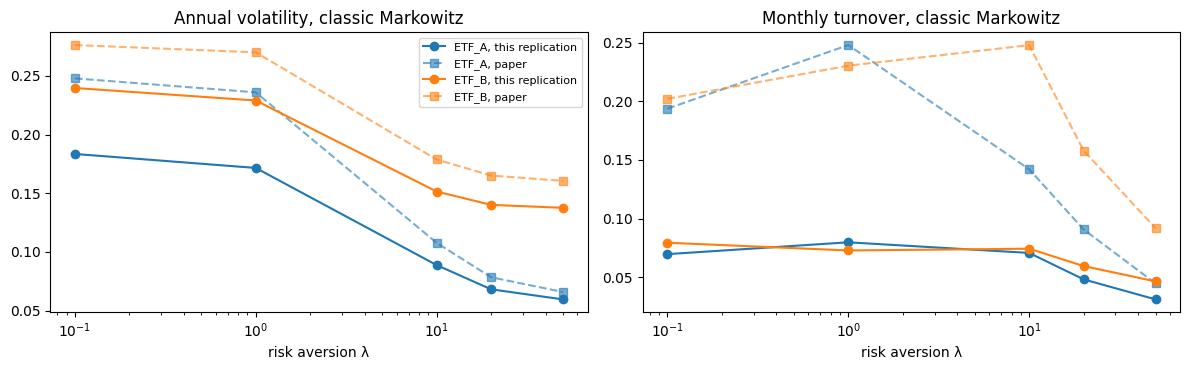

In [38]:
paper = backtest.paper_rows("MVO").set_index(["universe", "lam"])
metric_names = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover"]
side = []
for label, table in (("81 months", full), ("70 months", first70)):
    mk = table.loc["Classic Markowitz"][metric_names]
    for (u, lam), row in mk.iterrows():
        side.append({"window": label, "universe": u, "lam": lam,
                     **{f"{k}": row[k] for k in metric_names},
                     **{f"paper_{k}": paper.loc[(u, lam), k] for k in metric_names}})
comparison = pd.DataFrame(side)
show = comparison[comparison["window"] == "70 months"]
print("Classic Markowitz, first 70 months, next to Table 3")
print(show[["universe", "lam", "ann_vol", "paper_ann_vol", "turnover", "paper_turnover",
            "sharpe", "paper_sharpe", "max_drawdown", "paper_max_drawdown"]].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, title in ((axes[0], "ann_vol", "Annual volatility"), (axes[1], "turnover", "Monthly turnover")):
    for u, color in (("ETF_A", "tab:blue"), ("ETF_B", "tab:orange")):
        s = show[show["universe"] == u]
        ax.plot(s["lam"], s[metric], "o-", color=color, label=f"{u}, this replication")
        ax.plot(s["lam"], s[f"paper_{metric}"], "s--", color=color, alpha=0.6, label=f"{u}, paper")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"{title}, classic Markowitz")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Window for historical returns (WBS 3.35)

The paper does not state the window behind its "historical return estimates". The first run used 220 days, the covariance window. It matched the paper's volatility but traded only about a third as much: monthly turnover of 0.07 to 0.08 at low λ on ETF_A, against 0.19 to 0.25 in Table 3. A 220-day average changes little from month to month, so the portfolio rarely switches; a shorter window moves more and trades more.

This section reruns classic Markowitz with the expected return of each ETF averaged over 21, 42, 63, 126 and 220 trading days. Everything else stays as in section 9, including the 220-day covariance. Results are on the first 70 months, as in the paper.

**Rule for choosing the window, fixed before the results are seen.** For each window, the gap in turnover is the average of |log(turnover / paper's turnover)| over both universes and all five values of λ. Among the windows that still pass criteria 3 and 4 of the Replication Spec on ETF_A (volatility falls at each step of λ, turnover below 0.3, volatility within 30% of the paper at λ = 10, 20 and 50), the one with the smallest gap becomes the setting for classic Markowitz in the replication. Sharpe ratios are shown but play no part in the choice.

**Result.** 126 days (about six months) is closest. On ETF_A its turnover is 0.17, 0.18, 0.13, 0.08 and 0.05 across the λ grid, against 0.19, 0.25, 0.14, 0.09 and 0.05 in the paper. On ETF_B it still trades less than the paper (0.11 to 0.14 against 0.20 to 0.25 at low λ). The 21, 42 and 63-day windows trade more but fail the volatility criteria. At λ = 0.1 every window holds XLK most often in ETF_A, consistent with the paper's identical drawdown in both universes. `config.MU_DAYS` is set to 126, which sections 8 and 9 use.

In [39]:
paper_mvo = backtest.paper_rows("MVO").set_index(["universe", "lam"])
grid_rows, held_rows = [], []
for days in config.MU_DAYS_GRID:
    for u in ("ETF_A", "ETF_B"):
        mu_d = backtest.historical_means(clean, returns[u].index, u, days=days)
        for lam in config.LAMBDA_GRID:
            m, w = backtest.run(backtest.mean_variance(mu_d, cov_sample[u], lam), returns[u])
            keep = m["month"] <= config.PAPER_LAST_MONTH
            s = backtest.metrics(m[keep])
            grid_rows.append({"days": days, "universe": u, "lam": lam, **s[
                ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover", "effective_n"]].to_dict()})
            if lam == config.LAMBDA_GRID[0]:
                tw = w[w["date"].isin(m.loc[keep, "date"])]
                top = tw.loc[tw.groupby("date")["target"].idxmax(), "ticker"].value_counts()
                held_rows.append({"days": days, "universe": u, "main ETF": top.index[0],
                                  "share of months": top.iloc[0] / top.sum(),
                                  "max_drawdown": s["max_drawdown"]})

diag = pd.DataFrame(grid_rows)
diag = diag.join(paper_mvo[["ann_vol", "turnover"]].add_prefix("paper_"), on=["universe", "lam"])
diag["log_gap"] = np.log(diag["turnover"] / diag["paper_turnover"]).abs()

view = diag.pivot_table(index=["universe", "lam"], columns="days", values="turnover")
view["paper"] = paper_mvo["turnover"]
print("Monthly turnover by window (columns: trading days in the average), first 70 months")
print(view.round(3).to_string())

vol = diag.pivot_table(index=["universe", "lam"], columns="days", values="ann_vol")
vol["paper"] = paper_mvo["ann_vol"]
print()
print("Annual volatility by window, first 70 months")
print(vol.round(3).to_string())

Monthly turnover by window (columns: trading days in the average), first 70 months
days              21     42     63    126    220  paper
universe lam                                           
ETF_A    0.1   0.684  0.398  0.312  0.170  0.070  0.194
         1.0   0.661  0.410  0.319  0.180  0.080  0.248
         10.0  0.592  0.363  0.248  0.127  0.071  0.142
         20.0  0.450  0.220  0.156  0.081  0.048  0.091
         50.0  0.217  0.110  0.082  0.046  0.031  0.045
ETF_B    0.1   0.803  0.524  0.395  0.111  0.079  0.202
         1.0   0.810  0.549  0.400  0.132  0.073  0.230
         10.0  0.787  0.508  0.342  0.142  0.074  0.248
         20.0  0.625  0.354  0.228  0.092  0.059  0.158
         50.0  0.345  0.170  0.116  0.062  0.046  0.092


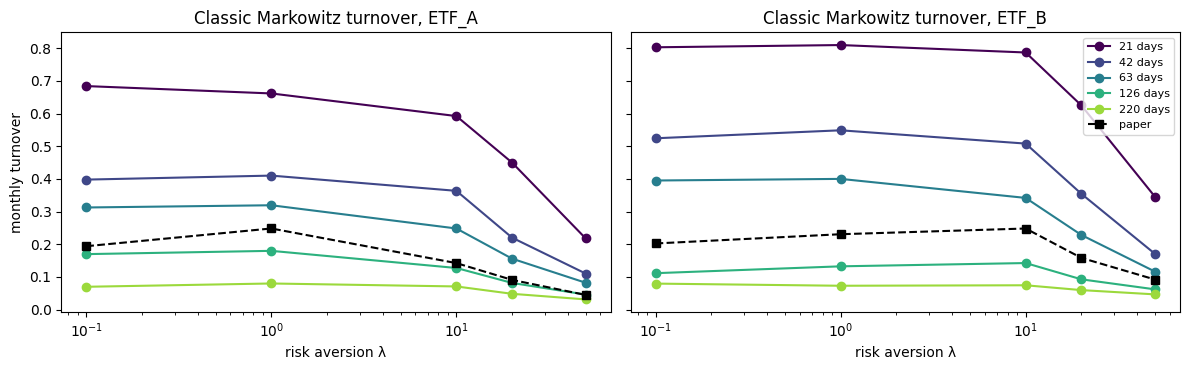

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.85, len(config.MU_DAYS_GRID)))
for ax, u in zip(axes, ("ETF_A", "ETF_B")):
    for days, c in zip(config.MU_DAYS_GRID, colors):
        s = diag[(diag["universe"] == u) & (diag["days"] == days)]
        ax.plot(s["lam"], s["turnover"], "o-", color=c, label=f"{days} days")
    p = paper_mvo.loc[u]
    ax.plot(p.index, p["turnover"], "s--", color="black", label="paper")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"Classic Markowitz turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [41]:
def passes(days):
    a = diag[(diag["universe"] == "ETF_A") & (diag["days"] == days)].sort_values("lam")
    falls = bool((a["ann_vol"].diff().dropna() < 0).all())
    low_turnover = bool((a["turnover"] < 0.3).all())
    hi = a[a["lam"] >= 10]
    close_vol = bool(((hi["ann_vol"] / hi["paper_ann_vol"] - 1).abs() <= 0.3).all())
    return falls and low_turnover and close_vol

choice = diag.groupby("days").agg(turnover_gap=("log_gap", "mean"),
                                  mean_turnover=("turnover", "mean"),
                                  mean_sharpe=("sharpe", "mean"))
choice["passes criteria 3 and 4"] = [passes(d) for d in choice.index]
print(choice.round(3).to_string())
eligible = choice[choice["passes criteria 3 and 4"]]
best = int(eligible["turnover_gap"].idxmin()) if len(eligible) else None
print()
print(f"Window closest to the paper's turnover: {best} days" if best else "No window passes criteria 3 and 4")

print()
print("ETF held most often at λ = 0.1 (the paper's drawdown there is -31.2% in both universes)")
print(pd.DataFrame(held_rows).round(3).to_string(index=False))

      turnover_gap  mean_turnover  mean_sharpe  passes criteria 3 and 4
days                                                                   
21           1.334          0.597        0.300                    False
42           0.791          0.361        0.471                    False
63           0.458          0.260        0.490                    False
126          0.334          0.114        0.642                     True
220          0.881          0.063        0.771                     True

Window closest to the paper's turnover: 126 days

ETF held most often at λ = 0.1 (the paper's drawdown there is -31.2% in both universes)
 days universe main ETF  share of months  max_drawdown
   21    ETF_A      XLK            0.343        -0.268
   21    ETF_B      XLK            0.257        -0.350
   42    ETF_A      XLK            0.386        -0.233
   42    ETF_B      XLE            0.343        -0.253
   63    ETF_A      XLK            0.400        -0.196
   63    ETF_B      XLE    

## 11. Save

Saves the tables, the benchmark results, the checks and an updated Variables list. An information file records the checksum of the raw download and the settings used.

In [42]:
out = DIRS["processed"]
daily_table.to_parquet(out / config.FILES["daily_table"], index=False)
daily_window_table.to_parquet(out / config.FILES["daily_windows"], index=False)
daily_window_table.to_csv(out / "Daily Training Windows.csv", index=False)
cov_table.to_parquet(out / config.FILES["covariances"], index=False)
variables.to_frame().to_csv(out / config.FILES["variables"], index=False)
benchmark_months.to_parquet(out / config.FILES["benchmark_months"], index=False)
results = full.reset_index(names=["strategy", "universe", "lam"])
results = results.merge(comparison[comparison["window"] == "81 months"][
    ["universe", "lam"] + [f"paper_{k}" for k in metric_names]], on=["universe", "lam"], how="left")
results.loc[results["strategy"] != "Classic Markowitz", [f"paper_{k}" for k in metric_names]] = np.nan
results.to_csv(DIRS["reports"] / config.FILES["benchmark_results"], index=False)
diag.to_csv(DIRS["reports"] / config.FILES["window_diagnostic"], index=False)
all_checks = pd.concat(checks, ignore_index=True)
all_checks.to_csv(DIRS["reports"] / config.FILES["daily_checks"], index=False)

info = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "raw_file_md5": raw_info["md5"],
    "rows": {u: int(n) for u, n in daily_table["universe"].value_counts().items()},
    "trading_days": int(daily_table["date"].nunique()),
    "forward_days": config.FORWARD_DAYS,
    "windows": {k: list(v) for k, v in config.DAILY_WINDOWS.items()},
    "covariance_days": config.COV_DAYS,
    "covariance_ridge": config.COV_RIDGE,
    "test_months": [config.TEST_FIRST_MONTH, config.TEST_LAST_MONTH],
    "fee": config.FEE,
    "lambda_grid": list(config.LAMBDA_GRID),
}
(out / config.FILES["daily_info"]).write_text(json.dumps(info, indent=2))
print("Saved: Daily Features, Daily Training Windows, Covariances, Benchmark Months,\n"
      "       Benchmark Results, Markowitz Window Diagnostic, Variables, Daily Data Checks")

Saved: Daily Features, Daily Training Windows, Covariances, Benchmark Months,
       Benchmark Results, Markowitz Window Diagnostic, Variables, Daily Data Checks


## 12. Summary

Key figures for the process log and the Data Specification sheet. After the run, save the notebook (File > Save) so the outputs are kept.

In [43]:
passed = int((all_checks["status"] == "PASS").sum())
failed = int((all_checks["status"] == "FAIL").sum())
print(f"Trading days:   {daily_table['date'].nunique():,} "
      f"({daily_table['date'].min():%Y-%m-%d} to {daily_table['date'].max():%Y-%m-%d})")
for u, n in daily_table["universe"].value_counts().sort_index().items():
    print(f"Daily rows {u}: {n:,}")
print(f"Windows:        {', '.join(config.DAILY_WINDOWS)}; {len(all_daily_windows['9+3'])} test months each")
print(f"Covariances:    {cov_table[['date', 'universe', 'method']].drop_duplicates().shape[0]:,} matrices")
print(f"Backtests:      {benchmark_months.groupby(['strategy', 'universe', 'lam'], dropna=False).ngroups} runs, "
      f"{benchmark_months['month'].nunique()} months each")
print(f"Checks:         {passed} passed, {failed} failed")

Trading days:   4,211 (2010-01-04 to 2026-09-30)
Daily rows ETF_A: 33,688
Daily rows ETF_B: 42,110
Windows:        9+3, 36, 60; 81 test months each
Covariances:    804 matrices
Backtests:      14 runs, 81 months each
Checks:         149 passed, 0 failed
